In [1]:
import os
import zipfile
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

np.random.seed(42)

In [2]:
datasets = {
    "SyntheticData.zip": "SyntheticData",
    "MNIST.zip": "MNIST",
    "IMAGEFEATUREDATASET.zip": "IMAGEFEATUREDATASET",
    "TIDIGITS.zip": "TIDIGITS"
}

for zip_name, folder_name in datasets.items():
    with zipfile.ZipFile(zip_name, "r") as z:
        z.extractall(folder_name)
    print(f"{zip_name} extracted successfully.")

SyntheticData.zip extracted successfully.
MNIST.zip extracted successfully.
IMAGEFEATUREDATASET.zip extracted successfully.
TIDIGITS.zip extracted successfully.


In [ ]:

synthetic_path = os.path.join(
    "SyntheticData",
    "SyntheticData",
    "SyntheticData",
    "team18",
    "data.pkl"
)

print("File exists:", os.path.exists(synthetic_path))

with open(synthetic_path, "rb") as file:
    synthetic_data = pickle.load(file)

X_synthetic = np.asarray(synthetic_data["x"])
y_synthetic = np.asarray(synthetic_data["y"]).ravel()

print("Feature shape:", X_synthetic.shape)
print("Label shape:", y_synthetic.shape)
print("Classes and counts:", np.unique(y_synthetic, return_counts=True))

File exists: True
Feature shape: (20000, 16)
Label shape: (20000,)
Classes and counts: (array([0, 1]), array([10000, 10000]))


In [9]:
def load_mnist_split(split):
    X, y = [], []

    for digit in [1, 3, 4]:
        folder = f"MNIST/TEAM_18/{split}/{digit}"

        for filename in os.listdir(folder):
            if filename.endswith(".png"):
                try:
                    img = Image.open(os.path.join(folder, filename)).convert("L")
                    X.append(np.asarray(img, dtype=np.float32).flatten() / 255.0)
                    y.append(digit)
                except Exception:
                    continue

    return np.array(X), np.array(y)


X_mnist_train, y_mnist_train = load_mnist_split("train")
X_mnist_val, y_mnist_val = load_mnist_split("dev")
X_mnist_test, y_mnist_test = load_mnist_split("test")

print("Train:", X_mnist_train.shape)
print("Validation:", X_mnist_val.shape)
print("Test:", X_mnist_test.shape)
print("Classes:", np.unique(y_mnist_train))

Train: (14950, 784)
Validation: (3765, 784)
Test: (3127, 784)
Classes: [1 3 4]


In [ ]:


image_path = os.path.join(
    "IMAGEFEATUREDATASET",
    "IMAGEFEATUREDATASET",
    "Team_18"
)

X_image_train = pd.read_csv(
    os.path.join(image_path, "train_data.csv"), header=None
).values

y_image_train = pd.read_csv(
    os.path.join(image_path, "train_label.csv"), header=None
).values.ravel()

X_image_val = pd.read_csv(
    os.path.join(image_path, "val_data.csv"), header=None
).values

y_image_val = pd.read_csv(
    os.path.join(image_path, "val_label.csv"), header=None
).values.ravel()

X_image_test = pd.read_csv(
    os.path.join(image_path, "test_data.csv"), header=None
).values

y_image_test = pd.read_csv(
    os.path.join(image_path, "test_label.csv"), header=None
).values.ravel()


print("Image dataset loaded successfully!")
print("Training:", X_image_train.shape, y_image_train.shape)
print("Validation:", X_image_val.shape, y_image_val.shape)
print("Testing:", X_image_test.shape, y_image_test.shape)
print("Classes:", np.unique(y_image_train))

Image dataset loaded successfully!
Training: (2000, 36) (2000,)
Validation: (500, 36) (500,)
Testing: (500, 36) (500,)
Classes: [0. 1. 2. 3. 4.]


In [ ]:


ti_path = os.path.join("TIDIGITS", "TIDIGITS", "Data")

for digit in [2, 4, 5]:
    file_path = os.path.join(ti_path, f"{digit}.npz")

    data = np.load(file_path, allow_pickle=True)

    print(f"\nDigit {digit}")
    print("Keys:", data.files)

    for key in data.files:
        print(key, data[key].shape, data[key].dtype)


Digit 2
Keys: ['arr_0', 'arr_1', 'arr_2', 'arr_3', 'arr_4', 'arr_5', 'arr_6', 'arr_7', 'arr_8', 'arr_9', 'arr_10', 'arr_11', 'arr_12', 'arr_13', 'arr_14', 'arr_15', 'arr_16', 'arr_17', 'arr_18', 'arr_19', 'arr_20', 'arr_21', 'arr_22', 'arr_23', 'arr_24', 'arr_25', 'arr_26', 'arr_27', 'arr_28', 'arr_29', 'arr_30', 'arr_31', 'arr_32', 'arr_33', 'arr_34', 'arr_35', 'arr_36', 'arr_37', 'arr_38', 'arr_39', 'arr_40', 'arr_41', 'arr_42', 'arr_43', 'arr_44', 'arr_45', 'arr_46', 'arr_47', 'arr_48', 'arr_49', 'arr_50', 'arr_51', 'arr_52', 'arr_53', 'arr_54', 'arr_55', 'arr_56', 'arr_57', 'arr_58', 'arr_59', 'arr_60', 'arr_61', 'arr_62', 'arr_63', 'arr_64', 'arr_65', 'arr_66', 'arr_67', 'arr_68', 'arr_69', 'arr_70', 'arr_71', 'arr_72', 'arr_73', 'arr_74', 'arr_75', 'arr_76', 'arr_77', 'arr_78', 'arr_79', 'arr_80', 'arr_81', 'arr_82', 'arr_83', 'arr_84', 'arr_85', 'arr_86', 'arr_87', 'arr_88', 'arr_89', 'arr_90', 'arr_91', 'arr_92', 'arr_93', 'arr_94', 'arr_95', 'arr_96', 'arr_97', 'arr_98', 'arr

In [ ]:


ti_path = os.path.join("TIDIGITS", "TIDIGITS", "Data")

ti_sequences = []
ti_labels = []

for digit in [2, 4, 5]:
    data = np.load(os.path.join(ti_path, f"{digit}.npz"))

    sequences = [
        data[key] for key in sorted(
            data.files, key=lambda k: int(k.split("_")[1])
        )
    ]

    ti_sequences.extend(sequences)
    ti_labels.extend([digit] * len(sequences))

y_ti = np.array(ti_labels)

X_ti = np.array([
    np.concatenate([seq.mean(axis=0), seq.std(axis=0)])
    for seq in ti_sequences
])

print("TI Digits loaded successfully!")
print("Utterances:", len(ti_sequences))
print("Feature shape:", X_ti.shape)
print("Labels:", np.unique(y_ti, return_counts=True))
print("First sequence shape:", ti_sequences[0].shape)

TI Digits loaded successfully!
Utterances: 1350
Feature shape: (1350, 78)
Labels: (array([2, 4, 5]), array([450, 450, 450]))
First sequence shape: (79, 39)


In [13]:
rng = np.random.RandomState(42)

train_indices = []
test_indices = []

for digit in [2, 4, 5]:
    indices = np.where(y_ti == digit)[0]
    rng.shuffle(indices)

    split = int(0.8 * len(indices))

    train_indices.extend(indices[:split])
    test_indices.extend(indices[split:])

train_indices = np.array(train_indices)
test_indices = np.array(test_indices)

X_ti_train = X_ti[train_indices]
y_ti_train = y_ti[train_indices]

X_ti_test = X_ti[test_indices]
y_ti_test = y_ti[test_indices]

ti_sequences_train = [ti_sequences[i] for i in train_indices]
ti_sequences_test = [ti_sequences[i] for i in test_indices]

print("Training:", X_ti_train.shape)
print("Testing:", X_ti_test.shape)
print("Training classes:", np.unique(y_ti_train, return_counts=True))
print("Testing classes:", np.unique(y_ti_test, return_counts=True))

Training: (1080, 78)
Testing: (270, 78)
Training classes: (array([2, 4, 5]), array([360, 360, 360]))
Testing classes: (array([2, 4, 5]), array([90, 90, 90]))


In [15]:
print("TI Digits dataset split")
print("-----------------------")
print("Training samples:", len(X_ti_train))
print("Testing samples:", len(X_ti_test))

print("\nTraining class distribution:")
print(dict(zip(*np.unique(y_ti_train, return_counts=True))))

print("\nTesting class distribution:")
print(dict(zip(*np.unique(y_ti_test, return_counts=True))))

print("\nTraining feature shape:", X_ti_train.shape)
print("Testing feature shape:", X_ti_test.shape)

TI Digits dataset split
-----------------------
Training samples: 1080
Testing samples: 270

Training class distribution:
{np.int64(2): np.int64(360), np.int64(4): np.int64(360), np.int64(5): np.int64(360)}

Testing class distribution:
{np.int64(2): np.int64(90), np.int64(4): np.int64(90), np.int64(5): np.int64(90)}

Training feature shape: (1080, 78)
Testing feature shape: (270, 78)


In [16]:
ti_mean = X_ti_train.mean(axis=0)
ti_std = X_ti_train.std(axis=0)
ti_std[ti_std == 0] = 1

X_ti_train_scaled = (X_ti_train - ti_mean) / ti_std
X_ti_test_scaled = (X_ti_test - ti_mean) / ti_std

print("TI Digits features standardized successfully!")
print("Training shape:", X_ti_train_scaled.shape)
print("Testing shape:", X_ti_test_scaled.shape)

TI Digits features standardized successfully!
Training shape: (1080, 78)
Testing shape: (270, 78)


In [17]:
def train_lda(X, y):
    classes = np.unique(y)
    means = {}
    priors = {}

    for c in classes:
        Xc = X[y == c]
        means[c] = Xc.mean(axis=0)
        priors[c] = len(Xc) / len(X)

    covariance = np.zeros((X.shape[1], X.shape[1]))

    for c in classes:
        Xc = X[y == c]
        diff = Xc - means[c]
        covariance += diff.T @ diff

    covariance /= (len(X) - len(classes))
    covariance += 1e-4 * np.eye(X.shape[1])

    return classes, means, priors, np.linalg.pinv(covariance)


def predict_lda(X, model):
    classes, means, priors, inv_cov = model
    scores = []

    for c in classes:
        mean = means[c]
        score = X @ inv_cov @ mean
        score -= 0.5 * mean @ inv_cov @ mean
        score += np.log(priors[c])
        scores.append(score)

    return classes[np.argmax(np.array(scores).T, axis=1)]


lda_model_ti = train_lda(X_ti_train_scaled, y_ti_train)
lda_predictions_ti = predict_lda(X_ti_test_scaled, lda_model_ti)

lda_accuracy_ti = np.mean(lda_predictions_ti == y_ti_test) * 100

print("TI Digits LDA Test Accuracy:", round(lda_accuracy_ti, 2), "%")

TI Digits LDA Test Accuracy: 34.44 %


In [18]:
def predict_knn(X, X_train, y_train, k=5):
    predictions = []

    for sample in X:
        distances = np.linalg.norm(X_train - sample, axis=1)
        nearest = np.argsort(distances)[:k]
        labels, counts = np.unique(y_train[nearest], return_counts=True)
        predictions.append(labels[np.argmax(counts)])

    return np.array(predictions)


knn_predictions_ti = predict_knn(
    X_ti_test_scaled, X_ti_train_scaled, y_ti_train, k=5
)

knn_accuracy_ti = np.mean(knn_predictions_ti == y_ti_test) * 100

print("TI Digits K-NN Test Accuracy:", round(knn_accuracy_ti, 2), "%")

TI Digits K-NN Test Accuracy: 42.96 %


In [19]:
def train_svm(X, y, learning_rate=0.001, epochs=1000, regularization=0.001):
    weights = np.zeros(X.shape[1])
    bias = 0.0

    for _ in range(epochs):
        for i in np.random.permutation(len(X)):
            condition = y[i] * (np.dot(X[i], weights) + bias)

            if condition >= 1:
                weights -= learning_rate * (2 * regularization * weights)
            else:
                weights -= learning_rate * (
                    2 * regularization * weights - y[i] * X[i]
                )
                bias += learning_rate * y[i]

    return weights, bias


def train_svm_ovr(X, y):
    models = {}

    for digit in np.unique(y):
        binary_y = np.where(y == digit, 1, -1)
        models[digit] = train_svm(X, binary_y)

    return models


def predict_svm_ovr(X, models):
    classes = list(models.keys())
    scores = []

    for digit in classes:
        weights, bias = models[digit]
        scores.append(X @ weights + bias)

    return np.array(classes)[np.argmax(np.array(scores).T, axis=1)]


svm_models_ti = train_svm_ovr(X_ti_train_scaled, y_ti_train)
svm_predictions_ti = predict_svm_ovr(X_ti_test_scaled, svm_models_ti)

svm_accuracy_ti = np.mean(svm_predictions_ti == y_ti_test) * 100

print("TI Digits SVM Test Accuracy:", round(svm_accuracy_ti, 2), "%")

TI Digits SVM Test Accuracy: 34.81 %


In [20]:
def train_gmm(X, n_components=3, max_iter=100):
    n, d = X.shape
    rng = np.random.RandomState(42)

    means = X[rng.choice(n, n_components, replace=False)].copy()
    variances = np.tile(X.var(axis=0) + 1e-4, (n_components, 1))
    weights = np.ones(n_components) / n_components

    for _ in range(max_iter):
        log_prob = np.zeros((n, n_components))

        for k in range(n_components):
            diff = X - means[k]
            log_det = np.sum(np.log(variances[k]))
            mahal = np.sum(diff**2 / variances[k], axis=1)
            log_prob[:, k] = (
                np.log(weights[k] + 1e-10)
                - 0.5 * (d * np.log(2 * np.pi) + log_det + mahal)
            )

        log_prob -= log_prob.max(axis=1, keepdims=True)
        responsibilities = np.exp(log_prob)
        responsibilities /= responsibilities.sum(axis=1, keepdims=True)

        Nk = responsibilities.sum(axis=0) + 1e-10
        weights = Nk / n
        means = (responsibilities.T @ X) / Nk[:, None]

        for k in range(n_components):
            diff = X - means[k]
            variances[k] = (
                responsibilities[:, k, None] * diff**2
            ).sum(axis=0) / Nk[k] + 1e-4

    return {"weights": weights, "means": means, "variances": variances}


def gmm_log_likelihood(X, model):
    n, d = X.shape
    scores = []

    for k in range(len(model["weights"])):
        diff = X - model["means"][k]
        var = model["variances"][k]
        score = (
            np.log(model["weights"][k] + 1e-10)
            - 0.5 * (
                d * np.log(2 * np.pi)
                + np.sum(np.log(var))
                + np.sum(diff**2 / var, axis=1)
            )
        )
        scores.append(score)

    scores = np.array(scores).T
    maximum = scores.max(axis=1)
    return maximum + np.log(np.exp(scores - maximum[:, None]).sum(axis=1))


gmm_models_ti = {
    digit: train_gmm(X_ti_train_scaled[y_ti_train == digit])
    for digit in np.unique(y_ti_train)
}

gmm_scores_ti = np.column_stack([
    gmm_log_likelihood(X_ti_test_scaled, gmm_models_ti[digit])
    for digit in np.unique(y_ti_train)
])

gmm_predictions_ti = np.unique(y_ti_train)[np.argmax(gmm_scores_ti, axis=1)]
gmm_accuracy_ti = np.mean(gmm_predictions_ti == y_ti_test) * 100

print("TI Digits GMM Test Accuracy:", round(gmm_accuracy_ti, 2), "%")

TI Digits GMM Test Accuracy: 43.33 %


In [ ]:
def dtw_distance(seq1, seq2):
    n, m = len(seq1), len(seq2)
    D = np.full((n + 1, m + 1), np.inf)
    D[0, 0] = 0

    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = np.linalg.norm(seq1[i-1] - seq2[j-1])
            D[i, j] = cost + min(
                D[i-1, j],
                D[i, j-1],
                D[i-1, j-1]
            )

    return D[n, m] / (n + m)


def resample_sequence(sequence, target_length=80):
    old_positions = np.linspace(0, 1, len(sequence))
    new_positions = np.linspace(0, 1, target_length)

    return np.column_stack([
        np.interp(new_positions, old_positions, sequence[:, j])
        for j in range(sequence.shape[1])
    ])


all_train_frames = np.vstack(ti_sequences_train)
frame_mean = all_train_frames.mean(axis=0)
frame_std = all_train_frames.std(axis=0)
frame_std[frame_std == 0] = 1

ti_train_dtw = [
    resample_sequence((seq - frame_mean) / frame_std)
    for seq in ti_sequences_train
]

ti_test_dtw = [
    resample_sequence((seq - frame_mean) / frame_std)
    for seq in ti_sequences_test
]

templates = {
    digit: [
        ti_train_dtw[i]
        for i in np.where(y_ti_train == digit)[0][:3]
    ]
    for digit in np.unique(y_ti_train)
}

dtw_predictions = []

for test_seq in ti_test_dtw:
    distances = {
        digit: np.mean([
            dtw_distance(test_seq, template)
            for template in templates[digit]
        ])
        for digit in templates
    }
    dtw_predictions.append(min(distances, key=distances.get))

dtw_predictions = np.array(dtw_predictions)
dtw_accuracy = np.mean(dtw_predictions == y_ti_test) * 100

print("TI Digits DTW Test Accuracy:", round(dtw_accuracy, 2), "%")

TI Digits DTW Test Accuracy: 95.56 %


In [ ]:
from numpy.linalg import eigh

cov_matrix = np.cov(X_ti_train_scaled, rowvar=False)

eigenvalues, eigenvectors = eigh(cov_matrix)

sorted_indices = np.argsort(eigenvalues)[::-1]
eigenvectors = eigenvectors[:, sorted_indices]

K_values = [10, 20, 30, 50]

X_ti_pca = {}

for k in K_values:
    components = eigenvectors[:, :k]

    X_ti_pca[k] = (
        X_ti_train_scaled @ components,
        X_ti_test_scaled @ components
    )

print("TI Digits PCA completed!")
for k in K_values:
    print(f"{k} components: Train {X_ti_pca[k][0].shape}, Test {X_ti_pca[k][1].shape}")

TI Digits PCA completed!
10 components: Train (1080, 10), Test (270, 10)
20 components: Train (1080, 20), Test (270, 20)
30 components: Train (1080, 30), Test (270, 30)
50 components: Train (1080, 50), Test (270, 50)


In [ ]:
ti_pca_results = []

for k in K_values:
    X_train_pca, X_test_pca = X_ti_pca[k]

    gmm_models = {
        c: train_gmm(X_train_pca[y_ti_train == c])
        for c in np.unique(y_ti_train)
    }
    scores = np.column_stack([
        gmm_log_likelihood(X_test_pca, gmm_models[c])
        for c in np.unique(y_ti_train)
    ])
    gmm_pred = np.unique(y_ti_train)[np.argmax(scores, axis=1)]

    lda_model = train_lda(X_train_pca, y_ti_train)
    lda_pred = predict_lda(X_test_pca, lda_model)

    knn_pred = predict_knn(
        X_test_pca, X_train_pca, y_ti_train, k=5
    )

    svm_models = train_svm_ovr(X_train_pca, y_ti_train)
    svm_pred = predict_svm_ovr(X_test_pca, svm_models)

    ti_pca_results.append({
        "PCA Components": k,
        "GMM": round(np.mean(gmm_pred == y_ti_test) * 100, 2),
        "LDA": round(np.mean(lda_pred == y_ti_test) * 100, 2),
        "K-NN": round(np.mean(knn_pred == y_ti_test) * 100, 2),
        "SVM": round(np.mean(svm_pred == y_ti_test) * 100, 2)
    })

ti_pca_results_df = pd.DataFrame(ti_pca_results)
print(ti_pca_results_df.to_string(index=False))

 PCA Components   GMM   LDA  K-NN   SVM
             10 37.41 33.70 35.93 28.52
             20 38.89 37.41 36.30 30.00
             30 35.93 34.44 35.93 35.19
             50 38.89 36.67 43.33 35.56


In [24]:
ti_comparison = pd.DataFrame({
    "Classifier": ["GMM", "LDA", "K-NN", "SVM"],
    "Original Test Accuracy (%)": [
        gmm_accuracy_ti,
        lda_accuracy_ti,
        knn_accuracy_ti,
        svm_accuracy_ti
    ],
    "Best PCA Components": [20, 20, 50, 50],
    "Best PCA Test Accuracy (%)": [38.89, 37.41, 43.33, 35.56]
})

ti_comparison["Improvement (%)"] = (
    ti_comparison["Best PCA Test Accuracy (%)"]
    - ti_comparison["Original Test Accuracy (%)"]
).round(2)

print(ti_comparison.to_string(index=False))

Classifier  Original Test Accuracy (%)  Best PCA Components  Best PCA Test Accuracy (%)  Improvement (%)
       GMM                   43.333333                   20                       38.89            -4.44
       LDA                   34.444444                   20                       37.41             2.97
      K-NN                   42.962963                   50                       43.33             0.37
       SVM                   34.814815                   50                       35.56             0.75


In [25]:
rng = np.random.RandomState(42)

synthetic_train_idx = []
synthetic_val_idx = []
synthetic_test_idx = []

for c in np.unique(y_synthetic):
    idx = np.where(y_synthetic == c)[0]
    rng.shuffle(idx)

    n_train = int(0.60 * len(idx))
    n_val = int(0.20 * len(idx))

    synthetic_train_idx.extend(idx[:n_train])
    synthetic_val_idx.extend(idx[n_train:n_train+n_val])
    synthetic_test_idx.extend(idx[n_train+n_val:])

X_syn_train = X_synthetic[synthetic_train_idx]
y_syn_train = y_synthetic[synthetic_train_idx]

X_syn_val = X_synthetic[synthetic_val_idx]
y_syn_val = y_synthetic[synthetic_val_idx]

X_syn_test = X_synthetic[synthetic_test_idx]
y_syn_test = y_synthetic[synthetic_test_idx]

print("Training:", X_syn_train.shape)
print("Validation:", X_syn_val.shape)
print("Testing:", X_syn_test.shape)

Training: (12000, 16)
Validation: (4000, 16)
Testing: (4000, 16)


In [26]:
syn_mean = X_syn_train.mean(axis=0)
syn_std = X_syn_train.std(axis=0)
syn_std[syn_std == 0] = 1

X_syn_train_scaled = (X_syn_train - syn_mean) / syn_std
X_syn_val_scaled = (X_syn_val - syn_mean) / syn_std
X_syn_test_scaled = (X_syn_test - syn_mean) / syn_std

print("Synthetic features standardized successfully!")

Synthetic features standardized successfully!


In [ ]:

syn_gmm_models = {
    c: train_gmm(X_syn_train_scaled[y_syn_train == c])
    for c in np.unique(y_syn_train)
}
syn_gmm_scores = np.column_stack([
    gmm_log_likelihood(X_syn_test_scaled, syn_gmm_models[c])
    for c in np.unique(y_syn_train)
])
syn_gmm_pred = np.unique(y_syn_train)[np.argmax(syn_gmm_scores, axis=1)]

syn_lda_model = train_lda(X_syn_train_scaled, y_syn_train)
syn_lda_pred = predict_lda(X_syn_test_scaled, syn_lda_model)

syn_knn_pred = predict_knn(
    X_syn_test_scaled, X_syn_train_scaled, y_syn_train, k=5
)

syn_svm_models = train_svm_ovr(X_syn_train_scaled, y_syn_train)
syn_svm_pred = predict_svm_ovr(X_syn_test_scaled, syn_svm_models)

syn_original_results = {
    "GMM": np.mean(syn_gmm_pred == y_syn_test) * 100,
    "LDA": np.mean(syn_lda_pred == y_syn_test) * 100,
    "K-NN": np.mean(syn_knn_pred == y_syn_test) * 100,
    "SVM": np.mean(syn_svm_pred == y_syn_test) * 100
}

print("Synthetic Original Feature Test Accuracy")
for name, accuracy in syn_original_results.items():
    print(f"{name}: {accuracy:.2f}%")

Synthetic Original Feature Test Accuracy
GMM: 97.67%
LDA: 96.20%
K-NN: 99.85%
SVM: 97.08%


In [28]:
cov_syn = np.cov(X_syn_train_scaled, rowvar=False)

eig_values, eig_vectors = np.linalg.eigh(cov_syn)

indices = np.argsort(eig_values)[::-1]
eig_vectors = eig_vectors[:, indices]

K_syn = [2, 4, 8, 12, 16]

X_syn_pca = {}

for k in K_syn:
    components = eig_vectors[:, :k]

    X_syn_pca[k] = (
        X_syn_train_scaled @ components,
        X_syn_test_scaled @ components
    )

print("Synthetic PCA completed!")

for k in K_syn:
    print(k, "components:", X_syn_pca[k][0].shape,
          X_syn_pca[k][1].shape)

Synthetic PCA completed!
2 components: (12000, 2) (4000, 2)
4 components: (12000, 4) (4000, 4)
8 components: (12000, 8) (4000, 8)
12 components: (12000, 12) (4000, 12)
16 components: (12000, 16) (4000, 16)


In [36]:
def train_svm_ovr_fast(X, y, epochs=300, learning_rate=0.01,
                       regularization=0.001):

    classes = np.unique(y)
    n, d = X.shape

    W = np.zeros((d, len(classes)))
    B = np.zeros(len(classes))

    Y = np.column_stack([
        np.where(y == c, 1.0, -1.0) for c in classes
    ])

    for _ in range(epochs):
        margins = Y * (X @ W + B)
        active = (margins < 1).astype(float)

        grad_W = regularization * W - X.T @ (Y * active) / n
        grad_B = -(Y * active).mean(axis=0)

        W -= learning_rate * grad_W
        B -= learning_rate * grad_B

    return classes, W, B


def predict_svm_ovr_fast(X, model):
    classes, W, B = model
    return classes[np.argmax(X @ W + B, axis=1)]


print("Optimized SVM functions ready!")

Optimized SVM functions ready!


In [ ]:
syn_pca_results = []

for k in K_syn:
    Xtr, Xte = X_syn_pca[k]

    models = {
        c: train_gmm(Xtr[y_syn_train == c], max_iter=50)
        for c in np.unique(y_syn_train)
    }

    scores = np.column_stack([
        gmm_log_likelihood(Xte, models[c])
        for c in np.unique(y_syn_train)
    ])
    pred_gmm = np.unique(y_syn_train)[np.argmax(scores, axis=1)]

    pred_lda = predict_lda(Xte, train_lda(Xtr, y_syn_train))

    pred_knn = predict_knn(Xte, Xtr, y_syn_train, k=5)

    svm_model = train_svm_ovr_fast(Xtr, y_syn_train)
    pred_svm = predict_svm_ovr_fast(Xte, svm_model)

    syn_pca_results.append({
        "PCA Components": k,
        "GMM": round(np.mean(pred_gmm == y_syn_test) * 100, 2),
        "LDA": round(np.mean(pred_lda == y_syn_test) * 100, 2),
        "K-NN": round(np.mean(pred_knn == y_syn_test) * 100, 2),
        "SVM": round(np.mean(pred_svm == y_syn_test) * 100, 2)
    })

syn_pca_df = pd.DataFrame(syn_pca_results)
print(syn_pca_df.to_string(index=False))


 PCA Components   GMM   LDA  K-NN   SVM
              2 86.58 86.02 85.82 86.45
              4 88.75 86.42 88.28 87.32
              8 96.52 94.12 97.15 93.45
             12 97.68 95.22 99.25 94.62
             16 98.50 96.20 99.85 95.10


In [ ]:

classes = np.unique(y_syn_train)

gmm_models = {
    c: train_gmm(X_syn_train_scaled[y_syn_train == c], max_iter=50)
    for c in classes
}
gmm_scores = np.column_stack([
    gmm_log_likelihood(X_syn_test_scaled, gmm_models[c])
    for c in classes
])
pred_gmm = classes[np.argmax(gmm_scores, axis=1)]

lda_model = train_lda(X_syn_train_scaled, y_syn_train)
pred_lda = predict_lda(X_syn_test_scaled, lda_model)

pred_knn = predict_knn(
    X_syn_test_scaled, X_syn_train_scaled, y_syn_train, k=5
)

svm_model = train_svm_ovr_fast(X_syn_train_scaled, y_syn_train)
pred_svm = predict_svm_ovr_fast(X_syn_test_scaled, svm_model)

syn_original_results = {
    "GMM": round(np.mean(pred_gmm == y_syn_test) * 100, 2),
    "LDA": round(np.mean(pred_lda == y_syn_test) * 100, 2),
    "K-NN": round(np.mean(pred_knn == y_syn_test) * 100, 2),
    "SVM": round(np.mean(pred_svm == y_syn_test) * 100, 2)
}

print("Original-feature test accuracies:")
print(syn_original_results)

Original-feature test accuracies:
{'GMM': np.float64(97.68), 'LDA': np.float64(96.2), 'K-NN': np.float64(99.85), 'SVM': np.float64(95.1)}


In [39]:
syn_original = {
    "GMM": 97.68,
    "LDA": 96.20,
    "K-NN": 99.85,
    "SVM": 95.10
}

syn_comparison = []

for classifier in syn_original:
    best_row = syn_pca_df.loc[
        syn_pca_df[classifier].idxmax()
    ]

    syn_comparison.append({
        "Classifier": classifier,
        "Original Accuracy (%)": syn_original[classifier],
        "Best PCA Components": int(best_row["PCA Components"]),
        "Best PCA Accuracy (%)": best_row[classifier],
        "Improvement (%)": round(
            best_row[classifier] - syn_original[classifier], 2
        )
    })

syn_comparison_df = pd.DataFrame(syn_comparison)
print(syn_comparison_df.to_string(index=False))

Classifier  Original Accuracy (%)  Best PCA Components  Best PCA Accuracy (%)  Improvement (%)
       GMM                  97.68                   16                  98.50             0.82
       LDA                  96.20                   16                  96.20             0.00
      K-NN                  99.85                   16                  99.85             0.00
       SVM                  95.10                   16                  95.10             0.00


In [40]:
print("MNIST dataset shapes:")
print("Training:", X_mnist_train.shape)
print("Validation:", X_mnist_val.shape)
print("Testing:", X_mnist_test.shape)

print("Classes:", np.unique(y_mnist_train))

MNIST dataset shapes:
Training: (14950, 784)
Validation: (3765, 784)
Testing: (3127, 784)
Classes: [1 3 4]


In [41]:
mnist_mean = X_mnist_train.mean(axis=0)
mnist_std = X_mnist_train.std(axis=0)

mnist_std[mnist_std == 0] = 1

X_mnist_train_scaled = (X_mnist_train - mnist_mean) / mnist_std
X_mnist_val_scaled = (X_mnist_val - mnist_mean) / mnist_std
X_mnist_test_scaled = (X_mnist_test - mnist_mean) / mnist_std

print("MNIST standardization completed!")
print("Training:", X_mnist_train_scaled.shape)
print("Validation:", X_mnist_val_scaled.shape)
print("Testing:", X_mnist_test_scaled.shape)

MNIST standardization completed!
Training: (14950, 784)
Validation: (3765, 784)
Testing: (3127, 784)


In [ ]:
mnist_classes = np.unique(y_mnist_train)

mnist_gmm_models = {
    c: train_gmm(
        X_mnist_train_scaled[y_mnist_train == c],
        n_components=3,
        max_iter=50
    )
    for c in mnist_classes
}

gmm_scores = np.column_stack([
    gmm_log_likelihood(X_mnist_test_scaled, mnist_gmm_models[c])
    for c in mnist_classes
])
pred_gmm = mnist_classes[np.argmax(gmm_scores, axis=1)]

mnist_lda_model = train_lda(
    X_mnist_train_scaled, y_mnist_train
)
pred_lda = predict_lda(
    X_mnist_test_scaled, mnist_lda_model
)

pred_knn = predict_knn(
    X_mnist_test_scaled,
    X_mnist_train_scaled,
    y_mnist_train,
    k=5
)

mnist_svm_model = train_svm_ovr_fast(
    X_mnist_train_scaled,
    y_mnist_train
)
pred_svm = predict_svm_ovr_fast(
    X_mnist_test_scaled,
    mnist_svm_model
)

mnist_original_results = {
    "GMM": round(np.mean(pred_gmm == y_mnist_test) * 100, 2),
    "LDA": round(np.mean(pred_lda == y_mnist_test) * 100, 2),
    "K-NN": round(np.mean(pred_knn == y_mnist_test) * 100, 2),
    "SVM": round(np.mean(pred_svm == y_mnist_test) * 100, 2)
}

print("MNIST Original-Feature Test Accuracies:")
print(mnist_original_results)

MNIST Original-Feature Test Accuracies:
{'GMM': np.float64(92.39), 'LDA': np.float64(98.69), 'K-NN': np.float64(98.94), 'SVM': np.float64(98.98)}


In [ ]:

cov_mnist = np.cov(X_mnist_train_scaled, rowvar=False)

eig_values, eig_vectors = np.linalg.eigh(cov_mnist)

indices = np.argsort(eig_values)[::-1]
eig_vectors = eig_vectors[:, indices]

K_mnist = [10, 20, 30, 50]

X_mnist_pca = {}

for k in K_mnist:
    Xtr = X_mnist_train_scaled @ eig_vectors[:, :k]
    Xte = X_mnist_test_scaled @ eig_vectors[:, :k]

    X_mnist_pca[k] = (Xtr, Xte)

print("MNIST PCA completed!")

for k in K_mnist:
    print(k, X_mnist_pca[k][0].shape, X_mnist_pca[k][1].shape)

MNIST PCA completed!
10 (14950, 10) (3127, 10)
20 (14950, 20) (3127, 20)
30 (14950, 30) (3127, 30)
50 (14950, 50) (3127, 50)


In [ ]:
mnist_pca_results = []

for k in K_mnist:
    Xtr, Xte = X_mnist_pca[k]

    models = {
        c: train_gmm(
            Xtr[y_mnist_train == c],
            n_components=3,
            max_iter=50
        )
        for c in mnist_classes
    }

    scores = np.column_stack([
        gmm_log_likelihood(Xte, models[c])
        for c in mnist_classes
    ])
    pred_gmm = mnist_classes[np.argmax(scores, axis=1)]

    pred_lda = predict_lda(
        Xte, train_lda(Xtr, y_mnist_train)
    )

    pred_knn = predict_knn(
        Xte, Xtr, y_mnist_train, k=5
    )

    svm_model = train_svm_ovr_fast(Xtr, y_mnist_train)
    pred_svm = predict_svm_ovr_fast(Xte, svm_model)

    mnist_pca_results.append({
        "PCA Components": k,
        "GMM": round(np.mean(pred_gmm == y_mnist_test) * 100, 2),
        "LDA": round(np.mean(pred_lda == y_mnist_test) * 100, 2),
        "K-NN": round(np.mean(pred_knn == y_mnist_test) * 100, 2),
        "SVM": round(np.mean(pred_svm == y_mnist_test) * 100, 2)
    })

mnist_pca_df = pd.DataFrame(mnist_pca_results)
print(mnist_pca_df.to_string(index=False))

 PCA Components   GMM   LDA  K-NN   SVM
             10 97.76 96.29 99.26 97.25
             20 97.83 97.60 99.49 98.43
             30 98.43 98.11 99.49 98.78
             50 95.62 98.27 99.39 98.85


In [45]:
mnist_original = {
    "GMM": 92.39,
    "LDA": 98.69,
    "K-NN": 98.94,
    "SVM": 98.98
}

mnist_comparison = []

for classifier in mnist_original:
    best_row = mnist_pca_df.loc[
        mnist_pca_df[classifier].idxmax()
    ]

    mnist_comparison.append({
        "Classifier": classifier,
        "Original Accuracy (%)": mnist_original[classifier],
        "Best PCA Components": int(best_row["PCA Components"]),
        "Best PCA Accuracy (%)": best_row[classifier],
        "Improvement (%)": round(
            best_row[classifier] - mnist_original[classifier], 2
        )
    })

mnist_comparison_df = pd.DataFrame(mnist_comparison)
print(mnist_comparison_df.to_string(index=False))

Classifier  Original Accuracy (%)  Best PCA Components  Best PCA Accuracy (%)  Improvement (%)
       GMM                  92.39                   30                  98.43             6.04
       LDA                  98.69                   50                  98.27            -0.42
      K-NN                  98.94                   20                  99.49             0.55
       SVM                  98.98                   50                  98.85            -0.13


In [46]:
print("Image dataset shapes:")
print("Training:", X_image_train.shape)
print("Validation:", X_image_val.shape)
print("Testing:", X_image_test.shape)
print("Classes:", np.unique(y_image_train))

Image dataset shapes:
Training: (2000, 36)
Validation: (500, 36)
Testing: (500, 36)
Classes: [0. 1. 2. 3. 4.]


In [47]:
image_mean = X_image_train.mean(axis=0)
image_std = X_image_train.std(axis=0)
image_std[image_std == 0] = 1

X_image_train_scaled = (X_image_train - image_mean) / image_std
X_image_val_scaled = (X_image_val - image_mean) / image_std
X_image_test_scaled = (X_image_test - image_mean) / image_std

print("Image standardization completed!")
print("Training:", X_image_train_scaled.shape)
print("Validation:", X_image_val_scaled.shape)
print("Testing:", X_image_test_scaled.shape)

Image standardization completed!
Training: (2000, 36)
Validation: (500, 36)
Testing: (500, 36)


In [ ]:
image_classes = np.unique(y_image_train)

image_gmm_models = {
    c: train_gmm(
        X_image_train_scaled[y_image_train == c],
        n_components=3,
        max_iter=50
    )
    for c in image_classes
}

gmm_scores = np.column_stack([
    gmm_log_likelihood(X_image_test_scaled, image_gmm_models[c])
    for c in image_classes
])
pred_gmm = image_classes[np.argmax(gmm_scores, axis=1)]

image_lda_model = train_lda(
    X_image_train_scaled, y_image_train
)
pred_lda = predict_lda(
    X_image_test_scaled, image_lda_model
)

pred_knn = predict_knn(
    X_image_test_scaled,
    X_image_train_scaled,
    y_image_train,
    k=5
)

image_svm_model = train_svm_ovr_fast(
    X_image_train_scaled, y_image_train
)
pred_svm = predict_svm_ovr_fast(
    X_image_test_scaled, image_svm_model
)

image_original_results = {
    "GMM": round(np.mean(pred_gmm == y_image_test) * 100, 2),
    "LDA": round(np.mean(pred_lda == y_image_test) * 100, 2),
    "K-NN": round(np.mean(pred_knn == y_image_test) * 100, 2),
    "SVM": round(np.mean(pred_svm == y_image_test) * 100, 2)
}

print("Image Original-Feature Test Accuracies:")
print(image_original_results)

Image Original-Feature Test Accuracies:
{'GMM': np.float64(48.6), 'LDA': np.float64(48.6), 'K-NN': np.float64(43.2), 'SVM': np.float64(44.8)}


In [49]:
cov_image = np.cov(X_image_train_scaled, rowvar=False)

eig_values, eig_vectors = np.linalg.eigh(cov_image)

indices = np.argsort(eig_values)[::-1]
eig_vectors = eig_vectors[:, indices]

K_image = [10, 20, 30, 36]

X_image_pca = {}

for k in K_image:
    Xtr = X_image_train_scaled @ eig_vectors[:, :k]
    Xte = X_image_test_scaled @ eig_vectors[:, :k]

    X_image_pca[k] = (Xtr, Xte)

print("Image PCA completed!")

for k in K_image:
    print(k, X_image_pca[k][0].shape, X_image_pca[k][1].shape)

Image PCA completed!
10 (2000, 10) (500, 10)
20 (2000, 20) (500, 20)
30 (2000, 30) (500, 30)
36 (2000, 36) (500, 36)


In [ ]:
image_pca_results = []

for k in K_image:
    Xtr, Xte = X_image_pca[k]

    models = {
        c: train_gmm(
            Xtr[y_image_train == c],
            n_components=3,
            max_iter=50
        )
        for c in image_classes
    }

    scores = np.column_stack([
        gmm_log_likelihood(Xte, models[c])
        for c in image_classes
    ])
    pred_gmm = image_classes[np.argmax(scores, axis=1)]

    pred_lda = predict_lda(
        Xte, train_lda(Xtr, y_image_train)
    )

    pred_knn = predict_knn(
        Xte, Xtr, y_image_train, k=5
    )


    svm_model = train_svm_ovr_fast(Xtr, y_image_train)
    pred_svm = predict_svm_ovr_fast(Xte, svm_model)

    image_pca_results.append({
        "PCA Components": k,
        "GMM": round(np.mean(pred_gmm == y_image_test) * 100, 2),
        "LDA": round(np.mean(pred_lda == y_image_test) * 100, 2),
        "K-NN": round(np.mean(pred_knn == y_image_test) * 100, 2),
        "SVM": round(np.mean(pred_svm == y_image_test) * 100, 2)
    })

image_pca_df = pd.DataFrame(image_pca_results)
print(image_pca_df.to_string(index=False))

 PCA Components  GMM  LDA  K-NN  SVM
             10 49.0 45.6  41.2 39.4
             20 52.8 46.0  45.0 41.8
             30 50.6 47.4  43.6 45.4
             36 49.2 48.6  43.2 44.8


In [51]:
image_original = {
    "GMM": 48.60,
    "LDA": 48.60,
    "K-NN": 43.20,
    "SVM": 44.80
}

image_comparison = []

for classifier in image_original:
    best_row = image_pca_df.loc[
        image_pca_df[classifier].idxmax()
    ]

    image_comparison.append({
        "Classifier": classifier,
        "Original Accuracy (%)": image_original[classifier],
        "Best PCA Components": int(best_row["PCA Components"]),
        "Best PCA Accuracy (%)": best_row[classifier],
        "Improvement (%)": round(
            best_row[classifier] - image_original[classifier], 2
        )
    })

image_comparison_df = pd.DataFrame(image_comparison)
print(image_comparison_df.to_string(index=False))

Classifier  Original Accuracy (%)  Best PCA Components  Best PCA Accuracy (%)  Improvement (%)
       GMM                   48.6                   20                   52.8              4.2
       LDA                   48.6                   36                   48.6              0.0
      K-NN                   43.2                   20                   45.0              1.8
       SVM                   44.8                   30                   45.4              0.6


In [54]:
ti_original = {
    "GMM": 43.33,
    "LDA": 34.44,
    "K-NN": 42.96,
    "SVM": 34.81
}

ti_pca_results = [
    {"PCA Components": 10, "GMM": 37.41, "LDA": 33.70, "K-NN": 35.93, "SVM": 28.52},
    {"PCA Components": 20, "GMM": 38.89, "LDA": 37.41, "K-NN": 36.30, "SVM": 30.00},
    {"PCA Components": 30, "GMM": 35.93, "LDA": 34.44, "K-NN": 35.93, "SVM": 35.19},
    {"PCA Components": 50, "GMM": 38.89, "LDA": 36.67, "K-NN": 43.33, "SVM": 35.56}
]

ti_pca_df = pd.DataFrame(ti_pca_results)

ti_comparison = []

for classifier in ti_original:
    best_row = ti_pca_df.loc[ti_pca_df[classifier].idxmax()]

    ti_comparison.append({
        "Classifier": classifier,
        "Original Accuracy (%)": ti_original[classifier],
        "Best PCA Components": int(best_row["PCA Components"]),
        "Best PCA Accuracy (%)": best_row[classifier],
        "Improvement (%)": round(
            best_row[classifier] - ti_original[classifier], 2
        )
    })

ti_comparison_df = pd.DataFrame(ti_comparison)
print(ti_comparison_df.to_string(index=False))

Classifier  Original Accuracy (%)  Best PCA Components  Best PCA Accuracy (%)  Improvement (%)
       GMM                  43.33                   20                  38.89            -4.44
       LDA                  34.44                   20                  37.41             2.97
      K-NN                  42.96                   50                  43.33             0.37
       SVM                  34.81                   50                  35.56             0.75


In [55]:
comparison_tables = {
    "Synthetic": syn_comparison_df,
    "MNIST": mnist_comparison_df,
    "Image": image_comparison_df,
    "TI Digits": ti_comparison_df
}

all_comparisons = []

for dataset, df in comparison_tables.items():
    temp = df.copy()
    temp.insert(0, "Dataset", dataset)
    all_comparisons.append(temp)

final_comparison_df = pd.concat(
    all_comparisons, ignore_index=True
)

print(final_comparison_df.to_string(index=False))

  Dataset Classifier  Original Accuracy (%)  Best PCA Components  Best PCA Accuracy (%)  Improvement (%)
Synthetic        GMM                  97.68                   16                  98.50             0.82
Synthetic        LDA                  96.20                   16                  96.20             0.00
Synthetic       K-NN                  99.85                   16                  99.85             0.00
Synthetic        SVM                  95.10                   16                  95.10             0.00
    MNIST        GMM                  92.39                   30                  98.43             6.04
    MNIST        LDA                  98.69                   50                  98.27            -0.42
    MNIST       K-NN                  98.94                   20                  99.49             0.55
    MNIST        SVM                  98.98                   50                  98.85            -0.13
    Image        GMM                  48.60            

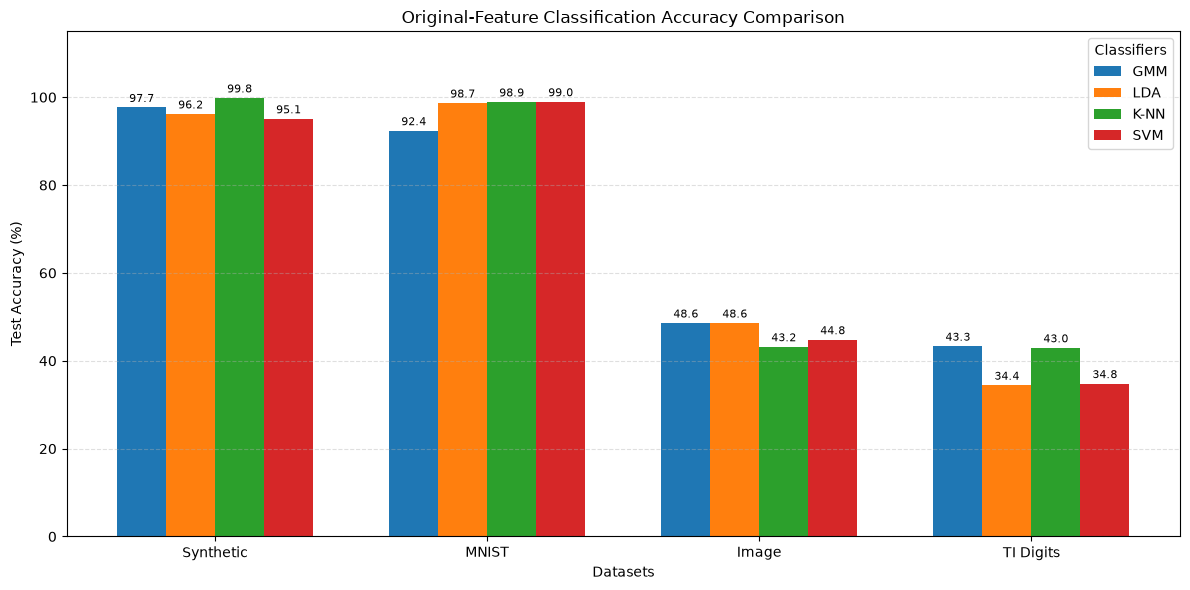

In [56]:

datasets = ["Synthetic", "MNIST", "Image", "TI Digits"]

accuracy = {
    "GMM": [97.68, 92.39, 48.60, 43.33],
    "LDA": [96.20, 98.69, 48.60, 34.44],
    "K-NN": [99.85, 98.94, 43.20, 42.96],
    "SVM": [95.10, 98.98, 44.80, 34.81]
}

x = np.arange(len(datasets))
width = 0.18

plt.figure(figsize=(12, 6))

for i, (classifier, values) in enumerate(accuracy.items()):
    bars = plt.bar(
        x + (i - 1.5) * width,
        values,
        width,
        label=classifier
    )

    plt.bar_label(bars, fmt="%.1f", fontsize=8, padding=2)

plt.xlabel("Datasets")
plt.ylabel("Test Accuracy (%)")
plt.title("Original-Feature Classification Accuracy Comparison")
plt.xticks(x, datasets)
plt.ylim(0, 115)
plt.legend(title="Classifiers")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("Plot_1_Original_Accuracy.png", dpi=300)
plt.show()

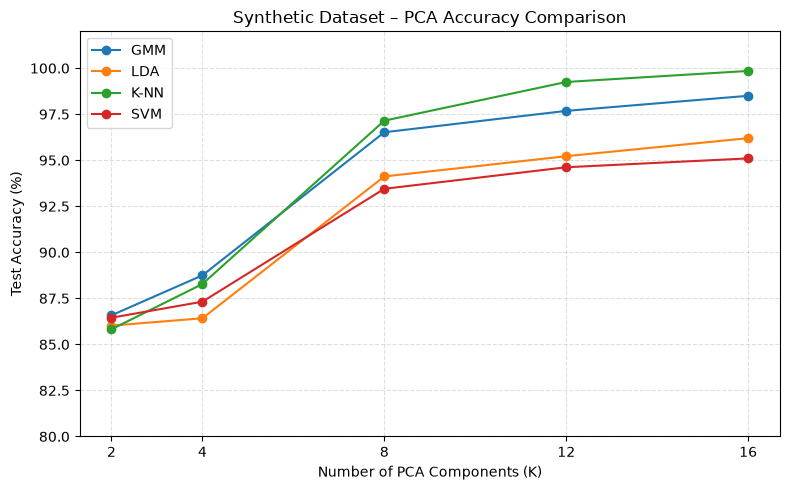

In [57]:

plt.figure(figsize=(8, 5))

for classifier in ["GMM", "LDA", "K-NN", "SVM"]:
    plt.plot(
        [2, 4, 8, 12, 16],
        [86.58, 88.75, 96.52, 97.68, 98.50] if classifier == "GMM" else
        [86.02, 86.42, 94.12, 95.22, 96.20] if classifier == "LDA" else
        [85.82, 88.28, 97.15, 99.25, 99.85] if classifier == "K-NN" else
        [86.45, 87.32, 93.45, 94.62, 95.10],
        marker="o",
        label=classifier
    )

plt.xlabel("Number of PCA Components (K)")
plt.ylabel("Test Accuracy (%)")
plt.title("Synthetic Dataset – PCA Accuracy Comparison")
plt.xticks([2, 4, 8, 12, 16])
plt.ylim(80, 102)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.savefig("Plot_2_Synthetic_PCA.png", dpi=300)
plt.show()

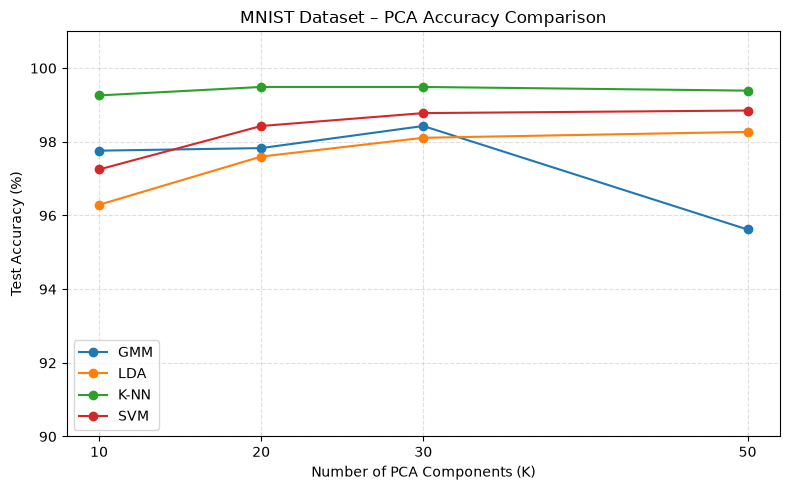

In [58]:
plt.figure(figsize=(8, 5))

pca_k = [10, 20, 30, 50]

mnist_accuracy = {
    "GMM": [97.76, 97.83, 98.43, 95.62],
    "LDA": [96.29, 97.60, 98.11, 98.27],
    "K-NN": [99.26, 99.49, 99.49, 99.39],
    "SVM": [97.25, 98.43, 98.78, 98.85]
}

for classifier, values in mnist_accuracy.items():
    plt.plot(pca_k, values, marker="o", label=classifier)

plt.xlabel("Number of PCA Components (K)")
plt.ylabel("Test Accuracy (%)")
plt.title("MNIST Dataset – PCA Accuracy Comparison")
plt.xticks(pca_k)
plt.ylim(90, 101)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.savefig("Plot_3_MNIST_PCA.png", dpi=300)
plt.show()

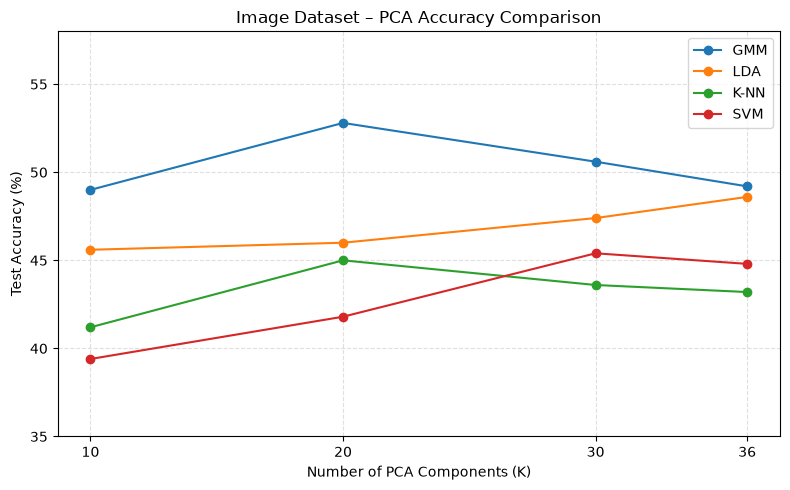

In [59]:
plt.figure(figsize=(8, 5))

pca_k = [10, 20, 30, 36]

image_accuracy = {
    "GMM": [49.0, 52.8, 50.6, 49.2],
    "LDA": [45.6, 46.0, 47.4, 48.6],
    "K-NN": [41.2, 45.0, 43.6, 43.2],
    "SVM": [39.4, 41.8, 45.4, 44.8]
}

for classifier, values in image_accuracy.items():
    plt.plot(pca_k, values, marker="o", label=classifier)

plt.xlabel("Number of PCA Components (K)")
plt.ylabel("Test Accuracy (%)")
plt.title("Image Dataset – PCA Accuracy Comparison")
plt.xticks(pca_k)
plt.ylim(35, 58)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.savefig("Plot_4_Image_PCA.png", dpi=300)
plt.show()

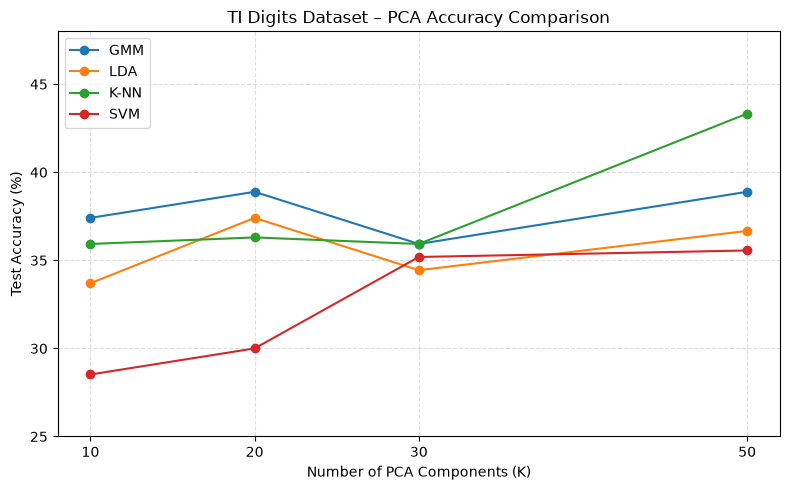

In [60]:
plt.figure(figsize=(8, 5))

pca_k = [10, 20, 30, 50]

ti_accuracy = {
    "GMM": [37.41, 38.89, 35.93, 38.89],
    "LDA": [33.70, 37.41, 34.44, 36.67],
    "K-NN": [35.93, 36.30, 35.93, 43.33],
    "SVM": [28.52, 30.00, 35.19, 35.56]
}

for classifier, values in ti_accuracy.items():
    plt.plot(pca_k, values, marker="o", label=classifier)

plt.xlabel("Number of PCA Components (K)")
plt.ylabel("Test Accuracy (%)")
plt.title("TI Digits Dataset – PCA Accuracy Comparison")
plt.xticks(pca_k)
plt.ylim(25, 48)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.savefig("Plot_5_TI_Digits_PCA.png", dpi=300)
plt.show()

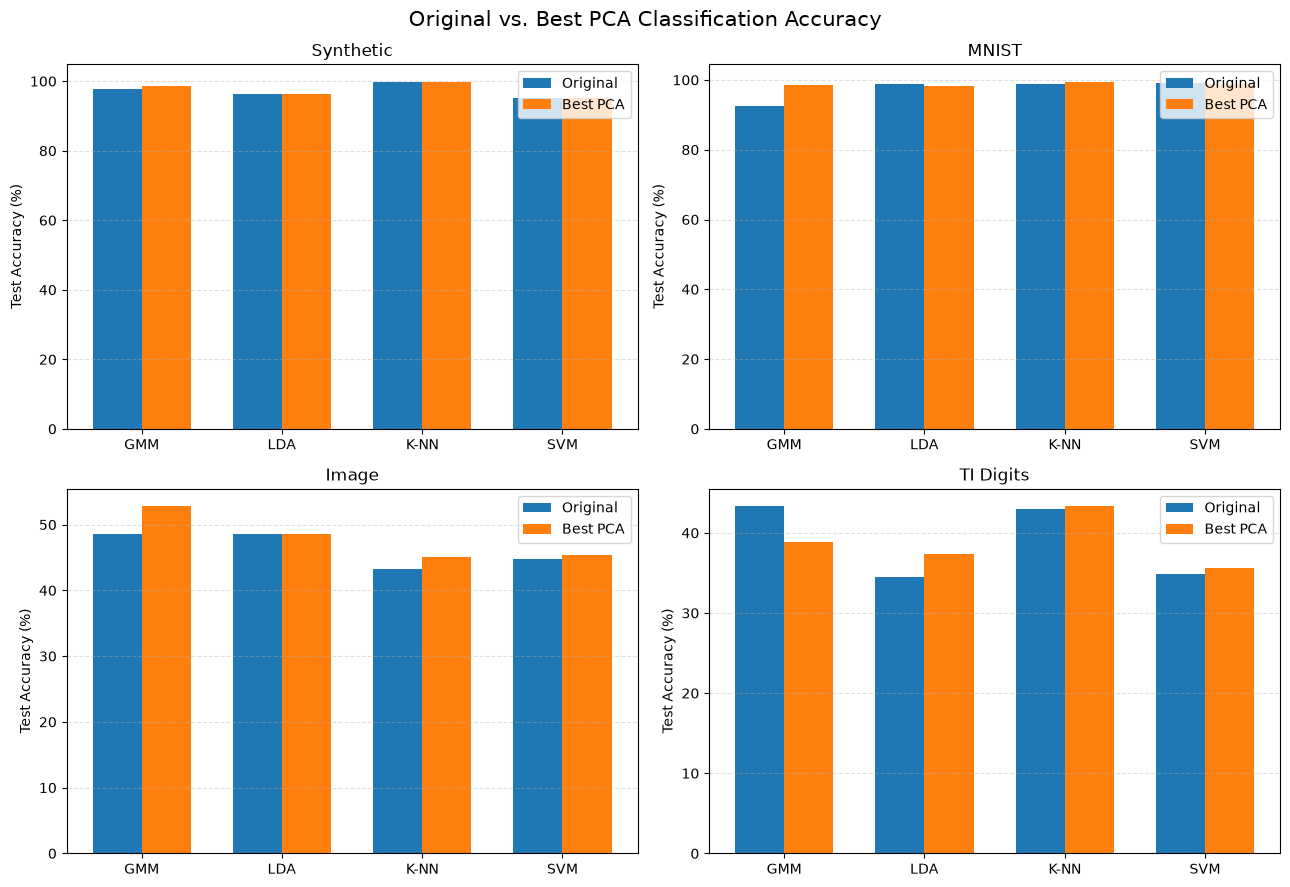

In [61]:
import matplotlib.pyplot as plt
import numpy as np

comparison = {
    "Synthetic": {
        "Original": [97.68, 96.20, 99.85, 95.10],
        "PCA": [98.50, 96.20, 99.85, 95.10]
    },
    "MNIST": {
        "Original": [92.39, 98.69, 98.94, 98.98],
        "PCA": [98.43, 98.27, 99.49, 98.85]
    },
    "Image": {
        "Original": [48.60, 48.60, 43.20, 44.80],
        "PCA": [52.80, 48.60, 45.00, 45.40]
    },
    "TI Digits": {
        "Original": [43.33, 34.44, 42.96, 34.81],
        "PCA": [38.89, 37.41, 43.33, 35.56]
    }
}

classifiers = ["GMM", "LDA", "K-NN", "SVM"]
datasets = list(comparison.keys())

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for ax, dataset in zip(axes, datasets):
    x = np.arange(len(classifiers))
    width = 0.35

    original = comparison[dataset]["Original"]
    pca = comparison[dataset]["PCA"]

    bars1 = ax.bar(x - width/2, original, width, label="Original")
    bars2 = ax.bar(x + width/2, pca, width, label="Best PCA")

    ax.set_title(dataset)
    ax.set_xticks(x)
    ax.set_xticklabels(classifiers)
    ax.set_ylabel("Test Accuracy (%)")
    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.4)

fig.suptitle("Original vs. Best PCA Classification Accuracy",
             fontsize=15)

plt.tight_layout()
plt.savefig("Plot_6_Original_vs_PCA.png", dpi=300)
plt.show()

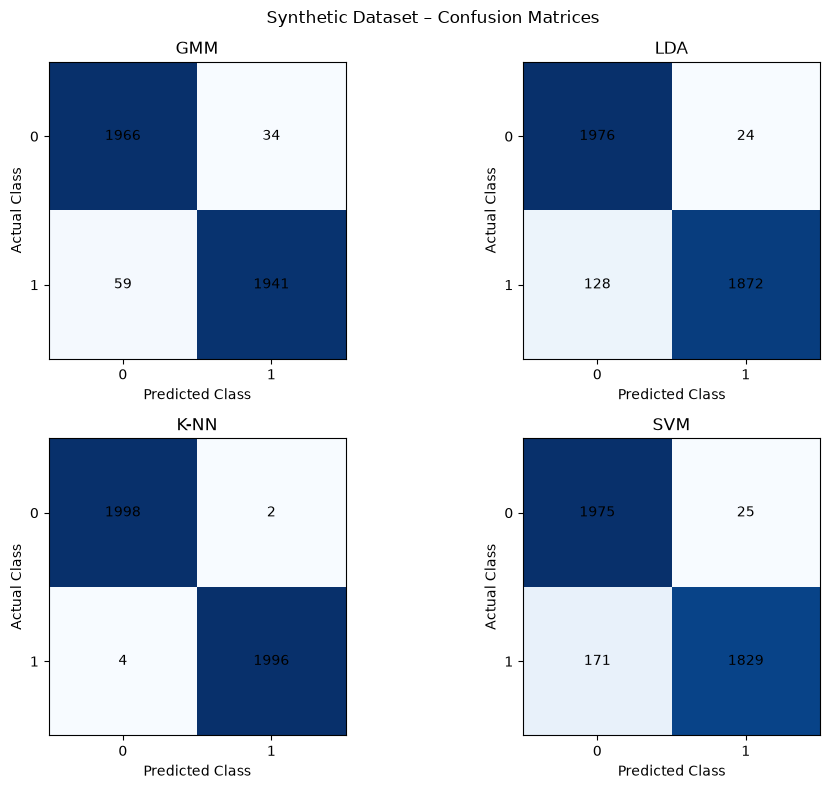

In [ ]:
def calculate_confusion_matrix(y_true, y_pred, classes):
    cm = np.zeros((len(classes), len(classes)), dtype=int)

    for actual, predicted in zip(y_true, y_pred):
        i = np.where(classes == actual)[0][0]
        j = np.where(classes == predicted)[0][0]
        cm[i, j] += 1

    return cm

classes = np.unique(y_syn_train)

gmm_models = {
    c: train_gmm(X_syn_train_scaled[y_syn_train == c])
    for c in classes
}

gmm_scores = np.column_stack([
    gmm_log_likelihood(X_syn_test_scaled, gmm_models[c])
    for c in classes
])
y_pred_gmm = classes[np.argmax(gmm_scores, axis=1)]

lda_model = train_lda(X_syn_train_scaled, y_syn_train)
y_pred_lda = predict_lda(X_syn_test_scaled, lda_model)

y_pred_knn = predict_knn(
    X_syn_test_scaled,
    X_syn_train_scaled,
    y_syn_train,
    k=5
)

svm_model = train_svm_ovr_fast(
    X_syn_train_scaled, y_syn_train
)
y_pred_svm = predict_svm_ovr_fast(
    X_syn_test_scaled, svm_model
)


predictions = {
    "GMM": y_pred_gmm,
    "LDA": y_pred_lda,
    "K-NN": y_pred_knn,
    "SVM": y_pred_svm
}

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, (name, y_pred) in zip(axes.flat, predictions.items()):

    cm = calculate_confusion_matrix(
        y_syn_test, y_pred, classes
    )

    ax.imshow(cm, cmap="Blues")

    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")
    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes)
    ax.set_yticklabels(classes)

    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, cm[i, j],
                    ha="center", va="center")

plt.suptitle("Synthetic Dataset – Confusion Matrices")
plt.tight_layout()
plt.savefig("Plot_7_Synthetic_Confusion_Matrices.png", dpi=300)
plt.show()

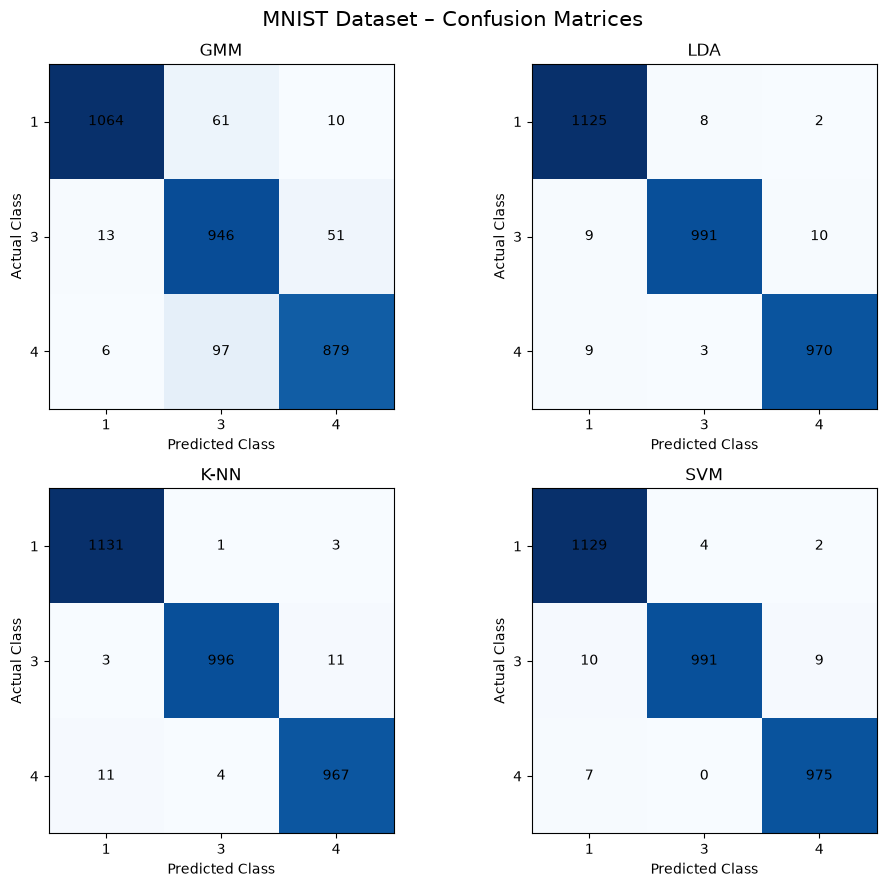

In [ ]:
classes = np.unique(y_mnist_train)

gmm_models_mnist = {
    c: train_gmm(X_mnist_train_scaled[y_mnist_train == c])
    for c in classes
}

gmm_scores = np.column_stack([
    gmm_log_likelihood(X_mnist_test_scaled, gmm_models_mnist[c])
    for c in classes
])
y_pred_gmm_mnist = classes[np.argmax(gmm_scores, axis=1)]

lda_model_mnist = train_lda(
    X_mnist_train_scaled, y_mnist_train
)
y_pred_lda_mnist = predict_lda(
    X_mnist_test_scaled, lda_model_mnist
)

y_pred_knn_mnist = predict_knn(
    X_mnist_test_scaled,
    X_mnist_train_scaled,
    y_mnist_train,
    k=5
)

svm_model_mnist = train_svm_ovr_fast(
    X_mnist_train_scaled, y_mnist_train
)
y_pred_svm_mnist = predict_svm_ovr_fast(
    X_mnist_test_scaled, svm_model_mnist
)

predictions_mnist = {
    "GMM": y_pred_gmm_mnist,
    "LDA": y_pred_lda_mnist,
    "K-NN": y_pred_knn_mnist,
    "SVM": y_pred_svm_mnist
}

fig, axes = plt.subplots(2, 2, figsize=(10, 9))

for ax, (name, y_pred) in zip(
    axes.flat, predictions_mnist.items()
):
    cm = calculate_confusion_matrix(
        y_mnist_test, y_pred, classes
    )

    ax.imshow(cm, cmap="Blues")
    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes)
    ax.set_yticklabels(classes)

    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, cm[i, j],
                    ha="center", va="center")

plt.suptitle(
    "MNIST Dataset – Confusion Matrices",
    fontsize=15
)
plt.tight_layout()
plt.savefig(
    "Plot_8_MNIST_Confusion_Matrices.png",
    dpi=300
)
plt.show()

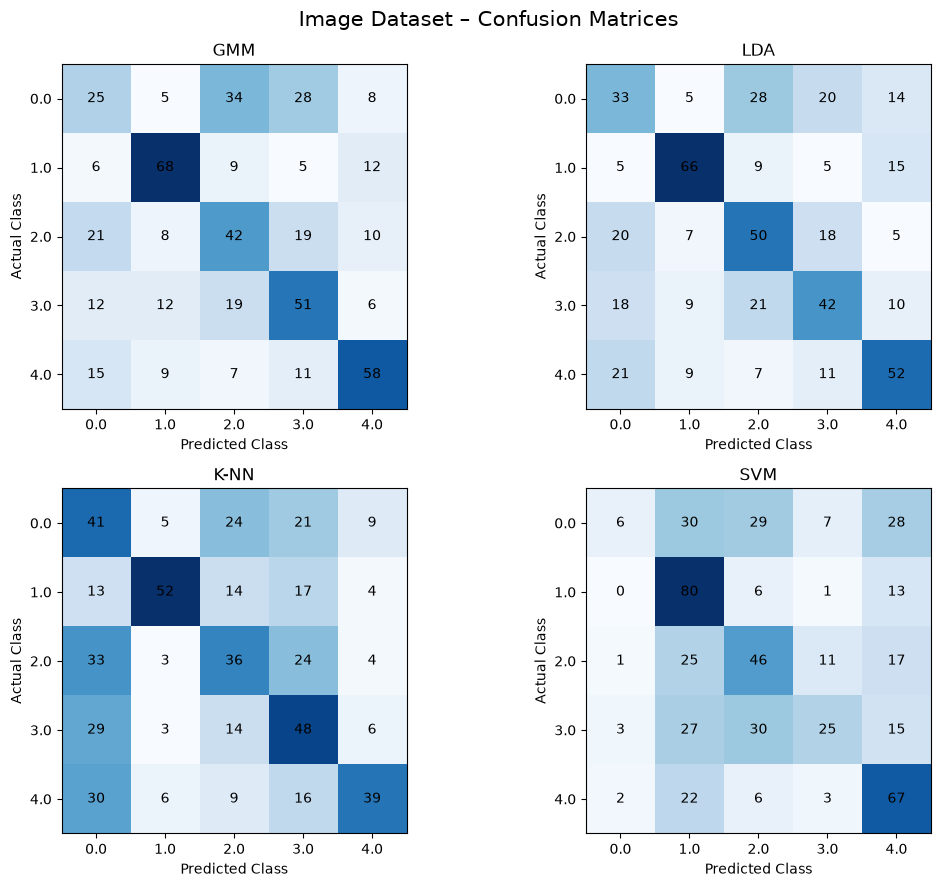

In [ ]:
classes = np.unique(y_image_train)

gmm_models_image = {
    c: train_gmm(X_image_train_scaled[y_image_train == c])
    for c in classes
}

gmm_scores = np.column_stack([
    gmm_log_likelihood(X_image_test_scaled, gmm_models_image[c])
    for c in classes
])

y_pred_gmm_image = classes[np.argmax(gmm_scores, axis=1)]


lda_model_image = train_lda(
    X_image_train_scaled, y_image_train
)

y_pred_lda_image = predict_lda(
    X_image_test_scaled, lda_model_image
)

y_pred_knn_image = predict_knn(
    X_image_test_scaled,
    X_image_train_scaled,
    y_image_train,
    k=5
)

svm_model_image = train_svm_ovr_fast(
    X_image_train_scaled, y_image_train
)

y_pred_svm_image = predict_svm_ovr_fast(
    X_image_test_scaled, svm_model_image
)

predictions_image = {
    "GMM": y_pred_gmm_image,
    "LDA": y_pred_lda_image,
    "K-NN": y_pred_knn_image,
    "SVM": y_pred_svm_image
}


fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, (name, y_pred) in zip(
    axes.flat, predictions_image.items()
):

    cm = calculate_confusion_matrix(
        y_image_test, y_pred, classes
    )

    ax.imshow(cm, cmap="Blues")
    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes)
    ax.set_yticklabels(classes)

    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(
                j, i, cm[i, j],
                ha="center", va="center"
            )

plt.suptitle(
    "Image Dataset – Confusion Matrices",
    fontsize=15
)

plt.tight_layout()
plt.savefig(
    "Plot_9_Image_Confusion_Matrices.png",
    dpi=300
)
plt.show()

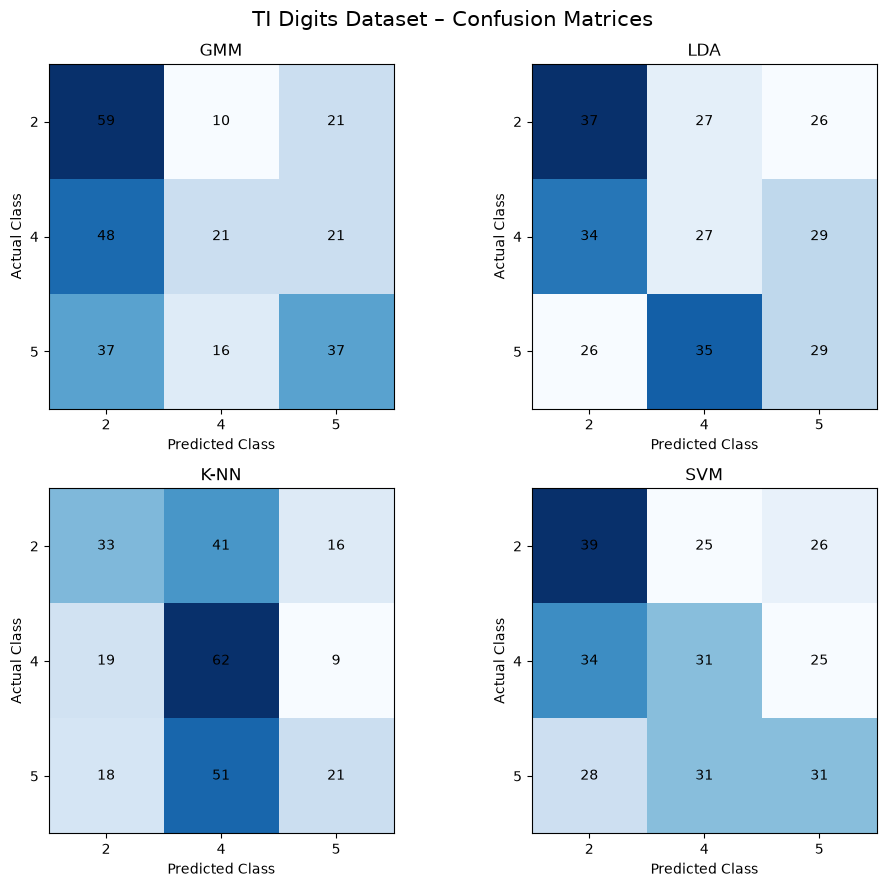

In [ ]:
classes = np.unique(y_ti_train)

gmm_models_ti = {
    c: train_gmm(X_ti_train_scaled[y_ti_train == c])
    for c in classes
}

gmm_scores = np.column_stack([
    gmm_log_likelihood(X_ti_test_scaled, gmm_models_ti[c])
    for c in classes
])

y_pred_gmm_ti = classes[np.argmax(gmm_scores, axis=1)]


lda_model_ti = train_lda(X_ti_train_scaled, y_ti_train)
y_pred_lda_ti = predict_lda(X_ti_test_scaled, lda_model_ti)


y_pred_knn_ti = predict_knn(
    X_ti_test_scaled,
    X_ti_train_scaled,
    y_ti_train,
    k=5
)

svm_model_ti = train_svm_ovr_fast(
    X_ti_train_scaled, y_ti_train
)

y_pred_svm_ti = predict_svm_ovr_fast(
    X_ti_test_scaled, svm_model_ti
)

predictions_ti = {
    "GMM": y_pred_gmm_ti,
    "LDA": y_pred_lda_ti,
    "K-NN": y_pred_knn_ti,
    "SVM": y_pred_svm_ti
}


fig, axes = plt.subplots(2, 2, figsize=(10, 9))

for ax, (name, y_pred) in zip(
    axes.flat, predictions_ti.items()
):
    cm = calculate_confusion_matrix(
        y_ti_test, y_pred, classes
    )

    ax.imshow(cm, cmap="Blues")
    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes)
    ax.set_yticklabels(classes)

    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, cm[i, j],
                    ha="center", va="center")

plt.suptitle(
    "TI Digits Dataset – Confusion Matrices",
    fontsize=15
)

plt.tight_layout()
plt.savefig(
    "Plot_10_TI_Digits_Confusion_Matrices.png",
    dpi=300
)
plt.show()